# Assignment 6 - Weather

This dataset is monthly weather data from Knock Airport, beginning in August 1996.

In [6]:
# Loading in the libraries and dataset, I'm using skip rows to filter out the descriptive rows at the beginning

import pandas as pd
import matplotlib.pyplot as plt

url = "https://clidata.met.ie/cli/climate_data/webdata/mly4935.csv"

weather = pd.read_csv(
    url,
    skiprows=19
)

weather.head()

,year,month,meant,maxtp,mintp,mnmax,mnmin,rain,gmin,wdsp,maxgt,sun
0,1996,8,13.4,20.4,7.3,16.6,10.3,109.4,5.3,8.3,34,
1,1996,10,9.7,,,12.5,7.0,,,,,
2,1996,11,5.0,,,7.6,2.5,,,,,
3,1996,12,3.1,10.7,-4.0,5.2,1.1,,-5.3,9.4,48,
4,1997,1,3.4,10.7,-3.9,5.2,1.6,26.0,-5.2,8.0,40,42.1


In [7]:
# Checking the columns 
weather.columns

Index(['year', 'month', 'meant', 'maxtp', 'mintp', 'mnmax', 'mnmin', 'rain',
       'gmin', 'wdsp', 'maxgt', 'sun'],
      dtype='object')

In [8]:
# Creating a day column using the first of each month
weather["Date"] = pd.to_datetime(
    dict(
        year=weather["year"],
        month=weather["month"],
        day=1
    ),
    errors="coerce"
)

weather[
    ["year", "month", "Date", "meant"]
].head()

,year,month,Date,meant
0,1996,8,1996-08-01,13.4
1,1996,10,1996-10-01,9.7
2,1996,11,1996-11-01,5.0
3,1996,12,1996-12-01,3.1
4,1997,1,1997-01-01,3.4


## Plot 1: The Temperature

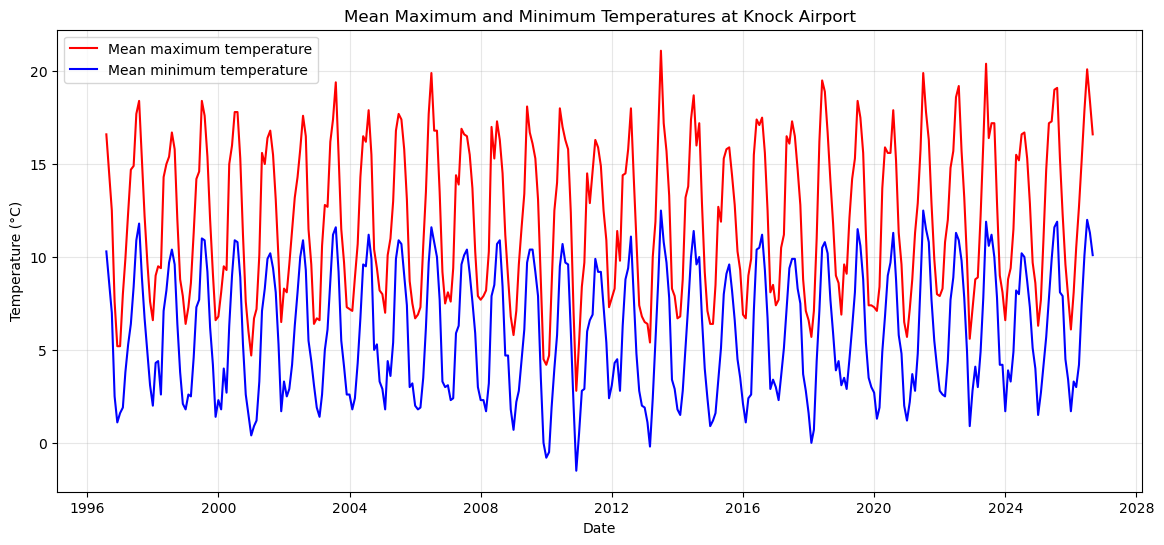

In [10]:
# Using the typical max and min temperatures for each month to plot

plt.figure(figsize=(14, 6))

plt.plot(
    weather["Date"],
    weather["mnmax"],
    label="Mean maximum temperature",
    color="red"
)

plt.plot(
    weather["Date"],
    weather["mnmin"],
    label="Mean minimum temperature",
    color="blue"
)

plt.title("Mean Maximum and Minimum Temperatures at Knock Airport")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

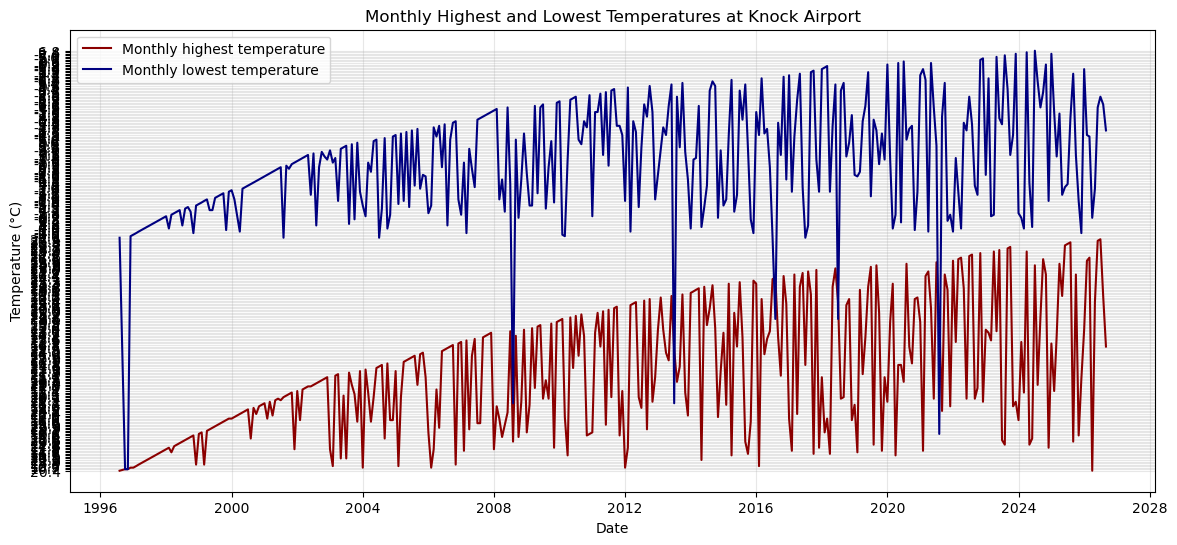

In [11]:
# Plotting the highest and lowest temperatures recorded during each month 
plt.figure(figsize=(14, 6))

plt.plot(
    weather["Date"],
    weather["maxtp"],
    label="Monthly highest temperature",
    color="darkred"
)

plt.plot(
    weather["Date"],
    weather["mintp"],
    label="Monthly lowest temperature",
    color="navy"
)

plt.title("Monthly Highest and Lowest Temperatures at Knock Airport")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

## Mean temperature over time

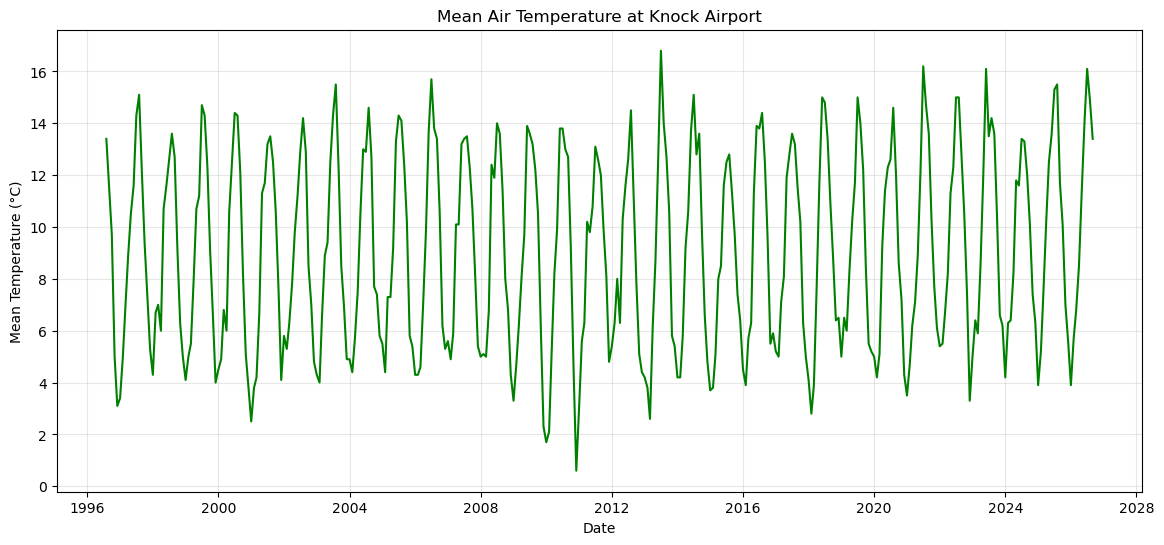

In [12]:
# MeanT in the dataset provides us with the mean air temperature so there is no need for manual calcs
plt.figure(figsize=(14, 6))

plt.plot(
    weather["Date"],
    weather["meant"],
    color="green"
)

plt.title("Mean Air Temperature at Knock Airport")
plt.xlabel("Date")
plt.ylabel("Mean Temperature (°C)")
plt.grid(True, alpha=0.3)

plt.show()

The assignment asks for the mean temperature by each day, however this dataset contains monthly data, where each row represents a month rather than a day. Therefore the mean was extracted from the data available.

## Plot 3: Mean temperature for each calendar month

In [13]:
# Calculating the monthly averages
mean_by_month = (
    weather
    .groupby("month")["meant"]
    .mean()
    .reindex(range(1, 13))
)

mean_by_month

month
1      4.313333
2      4.816667
3      5.940000
4      7.926667
5     10.560000
6     12.700000
7     14.116667
8     13.987097
9     12.360000
10     9.496667
11     6.556667
12     4.810000
Name: meant, dtype: float64

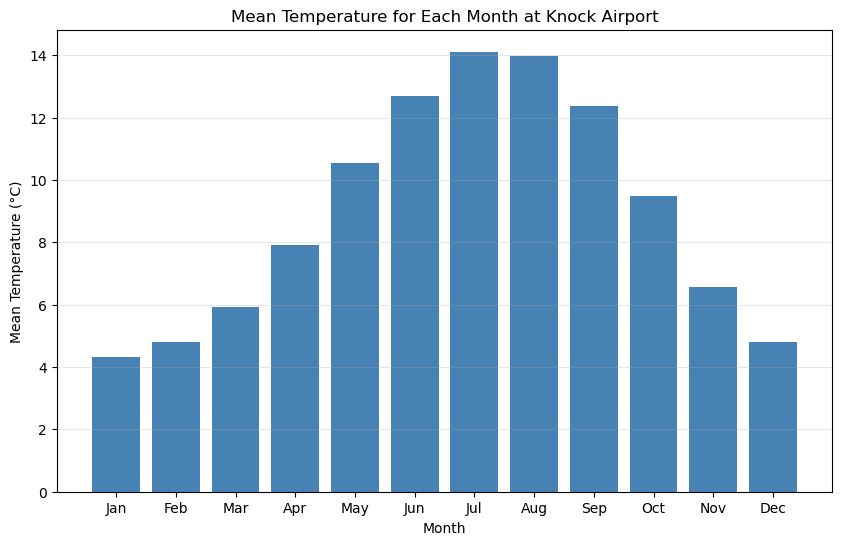

In [14]:
month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(10, 6))

plt.bar(
    month_names,
    mean_by_month,
    color="steelblue"
)

plt.title("Mean Temperature for Each Month at Knock Airport")
plt.xlabel("Month")
plt.ylabel("Mean Temperature (°C)")
plt.grid(axis="y", alpha=0.3)

plt.show()

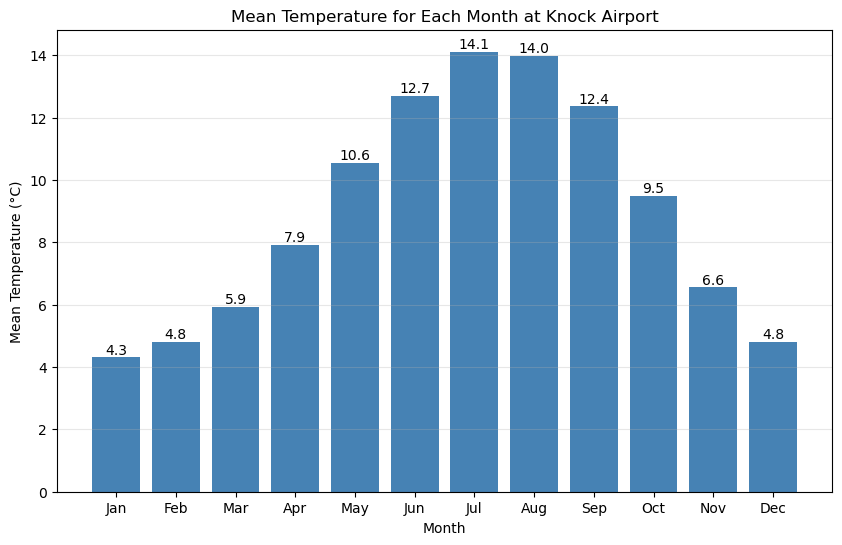

In [15]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    month_names,
    mean_by_month,
    color="steelblue"
)

plt.title("Mean Temperature for Each Month at Knock Airport")
plt.xlabel("Month")
plt.ylabel("Mean Temperature (°C)")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, mean_by_month):
    if pd.notna(value):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.1f}",
            ha="center",
            va="bottom"
        )

plt.show()